The analysis focuses on identifying patterns and associations related to booking cancellations, customer characteristics, booking behaviour, hotel type, market segment, deposit type, lead time, seasonality, and other relevant variables.

Part 0 — Project setup
- Import libraries
- Set random seed = 42
- Load hotel_bookings_cleaned.csv
- Verify shape and columns


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import binom
from statsmodels.stats.proportion import proportion_confint

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Plot settings
sns.set_theme()

print("Libraries imported successfully.")
print("Random seed:", RANDOM_SEED)

Libraries imported successfully.
Random seed: 42


In [2]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----------- ---------------------------- 3.1/11.3 MB 23.1 MB/s eta 0:00:01
   --------------------- ------------------ 6.0/11.3 MB 16.1 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.3 MB 14.9 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 13.8 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 12.0 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Load cleaned dataset
df = pd.read_csv("../data/processed/hotel_bookings_cleaned.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (87396, 37)


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Number of rows: 87396
Number of columns: 37

Columns:
1. IsCanceled
2. LeadTime
3. ArrivalDateYear
4. ArrivalDateMonth
5. ArrivalDateWeekNumber
6. ArrivalDateDayOfMonth
7. StaysInWeekendNights
8. StaysInWeekNights
9. Adults
10. Children
11. Babies
12. Meal
13. Country
14. MarketSegment
15. DistributionChannel
16. IsRepeatedGuest
17. PreviousCancellations
18. PreviousBookingsNotCanceled
19. ReservedRoomType
20. AssignedRoomType
21. BookingChanges
22. DepositType
23. Agent
24. Company
25. DaysInWaitingList
26. CustomerType
27. ADR
28. RequiredCarParkingSpaces
29. TotalOfSpecialRequests
30. ReservationStatus
31. ReservationStatusDate
32. Hotel
33. ArrivalDate
34. Season
35. TotalNights
36. TotalGuests
37. LeadTimeBand


Part 1 — Dataset overview
- Number of bookings
- Number of variables
- Hotel distribution
- Cancellation distribution
- Missing-value check


In [6]:
missing_values = df.isna().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

if missing_summary.empty:
    print("No missing values found.")
else:
    print(missing_summary)

No missing values found.


In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

dtype_summary

Number of duplicate rows: 0


,Column,Data Type
0,IsCanceled,int64
1,LeadTime,int64
2,ArrivalDateYear,int64
3,ArrivalDateMonth,str
4,ArrivalDateWeekNumber,int64
5,ArrivalDateDayOfMonth,int64
6,StaysInWeekendNights,int64
7,StaysInWeekNights,int64
8,Adults,int64
9,Children,float64


In [9]:
print("Unique IsCanceled values:")
print(sorted(df["IsCanceled"].unique()))
print("\nCancellation counts:")
print(df["IsCanceled"].value_counts().sort_index())
print("\nCancellation proportions:")
print(
    df["IsCanceled"]
    .value_counts(normalize=True)
    .sort_index()
)
overall_cancellation_rate = df["IsCanceled"].mean()

print(
    f"\nOverall cancellation rate: "
    f"{overall_cancellation_rate:.4f}"
)

print(
    f"Overall cancellation rate: "
    f"{overall_cancellation_rate * 100:.2f}%"
)

Unique IsCanceled values:
[np.int64(0), np.int64(1)]

Cancellation counts:
IsCanceled
0    63371
1    24025
Name: count, dtype: int64

Cancellation proportions:
IsCanceled
0    0.725102
1    0.274898
Name: proportion, dtype: float64

Overall cancellation rate: 0.2749
Overall cancellation rate: 27.49%


In [10]:
dataset_summary = pd.DataFrame({
    "Measure": [
        "Number of bookings",
        "Number of variables",
        "Cancelled bookings",
        "Non-cancelled bookings",
        "Overall cancellation rate"
    ],
    "Value": [
        len(df),
        df.shape[1],
        int(df["IsCanceled"].sum()),
        int((df["IsCanceled"] == 0).sum()),
        f"{df['IsCanceled'].mean() * 100:.2f}%"
    ]
})

dataset_summary

,Measure,Value
0,Number of bookings,87396
1,Number of variables,37
2,Cancelled bookings,24025
3,Non-cancelled bookings,63371
4,Overall cancellation rate,27.49%


Categorical attribute check


In [11]:
categorical_columns = [
    "Hotel",
    "MarketSegment",
    "DistributionChannel",
    "DepositType",
    "CustomerType",
    "Season",
    "LeadTimeBand",
    "IsRepeatedGuest"
]

for column in categorical_columns:
    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)
    print(df[column].value_counts(dropna=False))


Hotel
Hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

MarketSegment
MarketSegment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64

DistributionChannel
DistributionChannel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64

DepositType
DepositType
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64

CustomerType
CustomerType
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64

Season
Season
Summer    29079
Spring    23776
Autumn    18619
Winter    15922
Name: count, dtype: int64

LeadTimeBand
LeadTimeBand
1-3mo    22744
0-7d     18304
3-6mo    18243
1-4wk    16340
6mo+     11765
Name: count, dtype: int64

IsRepeatedGuest
Is

Numerical attribute check


In [12]:
numeric_columns = [
    "LeadTime",
    "ADR",
    "TotalNights",
    "TotalGuests",
    "Adults",
    "Children",
    "Babies",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "BookingChanges",
    "DaysInWaitingList",
    "TotalOfSpecialRequests"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
LeadTime,87396.0,79.891368,86.052325,0.0,11.0,49.0,125.0,737.0
ADR,87396.0,106.338229,55.012707,0.0,72.0,98.1,134.0,5400.0
TotalNights,87396.0,3.630658,2.763449,0.0,2.0,3.0,5.0,69.0
TotalGuests,87396.0,2.025253,0.794319,0.0,2.0,2.0,2.0,55.0
Adults,87396.0,1.875795,0.626500,0.0,2.0,2.0,2.0,55.0
Children,87396.0,0.138633,0.455871,0.0,0.0,0.0,0.0,10.0
Babies,87396.0,0.010824,0.113597,0.0,0.0,0.0,0.0,10.0
PreviousCancellations,87396.0,0.030413,0.369145,0.0,0.0,0.0,0.0,26.0
PreviousBookingsNotCanceled,87396.0,0.183990,1.731894,0.0,0.0,0.0,0.0,72.0
BookingChanges,87396.0,0.271603,0.727245,0.0,0.0,0.0,0.0,21.0


In [13]:
print("Years:")
print(sorted(df["ArrivalDateYear"].unique()))

print("\nMonths by year:")

months_by_year = (
    df.groupby("ArrivalDateYear")["ArrivalDateMonth"]
    .unique()
)

for year, months in months_by_year.items():
    print(year, ":", list(months))

Years:
[np.int64(2015), np.int64(2016), np.int64(2017)]

Months by year:
2015 : ['July', 'August', 'September', 'October', 'November', 'December']
2016 : ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
2017 : ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']


checks

In [14]:
print("Season values:")
print(df["Season"].value_counts())

print("\nLeadTimeBand values:")
print(df["LeadTimeBand"].value_counts())

print("\nTotalNights summary:")
print(df["TotalNights"].describe())

print("\nTotalGuests summary:")
print(df["TotalGuests"].describe())

Season values:
Season
Summer    29079
Spring    23776
Autumn    18619
Winter    15922
Name: count, dtype: int64

LeadTimeBand values:
LeadTimeBand
1-3mo    22744
0-7d     18304
3-6mo    18243
1-4wk    16340
6mo+     11765
Name: count, dtype: int64

TotalNights summary:
count    87396.000000
mean         3.630658
std          2.763449
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         69.000000
Name: TotalNights, dtype: float64

TotalGuests summary:
count    87396.000000
mean         2.025253
std          0.794319
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max         55.000000
Name: TotalGuests, dtype: float64


Part 2 — Cancellation EDA

1. Cancellation by Hotel
2. Cancellation by Market Segment
3. Cancellation by Deposit Type
4. Cancellation by LeadTimeBand
5. Cancellation by Customer Type
6. Cancellation by Repeated Guest
7. Cancellation by Previous Cancellations

## 1. Cancellation Baseline

Before comparing cancellation behaviour across hotels, market segments, booking channels, or customer characteristics, we first establish the overall cancellation rate in the cleaned dataset.

The variable `IsCanceled` represents cancellation status, where 1 indicates a cancelled booking and 0 indicates a non-cancelled booking.

This overall rate provides a baseline for interpreting the group-level cancellation rates explored in the following sections.

In [15]:
# Overall cancellation baseline

cancellation_counts = (
    df["IsCanceled"]
    .value_counts()
    .sort_index()
)

cancellation_rate = df["IsCanceled"].mean()

print("Cancellation counts:")
print(cancellation_counts)

print(f"\nOverall cancellation rate: {cancellation_rate:.4f}")
print(f"Overall cancellation rate: {cancellation_rate * 100:.2f}%")

Cancellation counts:
IsCanceled
0    63371
1    24025
Name: count, dtype: int64

Overall cancellation rate: 0.2749
Overall cancellation rate: 27.49%


In [16]:
# Create a summary table

cancellation_summary = pd.DataFrame({
    "Status": ["Not Cancelled", "Cancelled"],
    "Bookings": [
        (df["IsCanceled"] == 0).sum(),
        (df["IsCanceled"] == 1).sum()
    ],
})

cancellation_summary["Percentage"] = (
    cancellation_summary["Bookings"]
    / len(df)
    * 100
)

cancellation_summary

,Status,Bookings,Percentage
0,Not Cancelled,63371,72.510184
1,Cancelled,24025,27.489816


## 2. Cancellation by Hotel

**Question:** Is cancellation behaviour different between City Hotel and Resort Hotel?

**Graph:** The bar chart compares the observed cancellation rate for each hotel type. The number of bookings (`n`) is shown for each group, together with 95% confidence intervals for the estimated cancellation proportions.

**Observation:** The cancellation rates of City Hotel and Resort Hotel are compared against the overall cancellation rate established above.

**Possible explanation:** Differences between the two hotel types may be linked to differences in booking composition, market segment, customer characteristics, booking channel, or other factors.

**Statistical question:** Is hotel type statistically associated with cancellation status?

**Interpretation rule:** The observed difference represents an association in this dataset and does not establish that hotel type causes cancellation.

In [17]:
def cancellation_rate_summary(data, group_column):
    """
    Calculate cancellation count, booking count,
    cancellation rate, and 95% Wilson confidence interval.
    """
    
    summary = (
        data.groupby(group_column)["IsCanceled"]
        .agg(
            cancelled="sum",
            n="count"
        )
        .reset_index()
    )

    summary["rate"] = summary["cancelled"] / summary["n"]

    ci_low, ci_high = proportion_confint(
        summary["cancelled"],
        summary["n"],
        alpha=0.05,
        method="wilson"
    )

    summary["ci_low"] = ci_low
    summary["ci_high"] = ci_high

    summary["rate_percent"] = summary["rate"] * 100
    summary["ci_low_percent"] = summary["ci_low"] * 100
    summary["ci_high_percent"] = summary["ci_high"] * 100

    return summary

calculate hotel cancellation rates

In [18]:
hotel_summary = cancellation_rate_summary(
    df,
    "Hotel"
)

hotel_summary

,Hotel,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,City Hotel,16049,53428,0.300386,0.296513,0.304287,30.038557,29.651287,30.428696
1,Resort Hotel,7976,33968,0.234809,0.230332,0.239347,23.480923,23.033167,23.934677


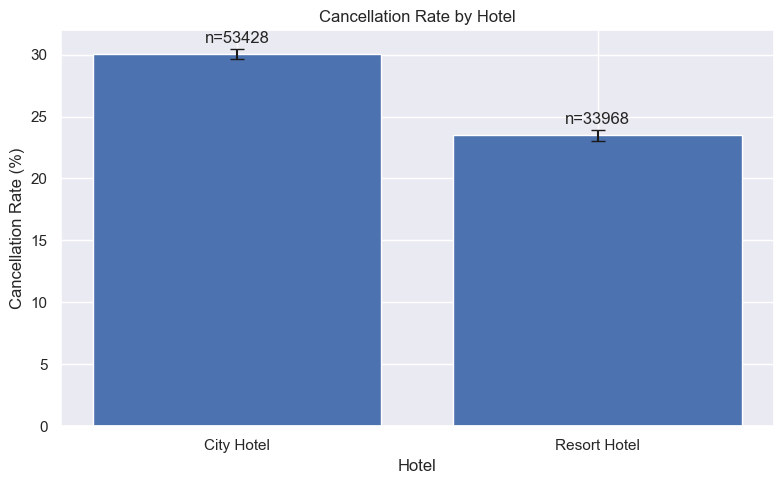

In [19]:
plt.figure(figsize=(8, 5))

x = np.arange(len(hotel_summary))

rates = hotel_summary["rate_percent"].values

lower_error = (
    hotel_summary["rate_percent"]
    - hotel_summary["ci_low_percent"]
).values

upper_error = (
    hotel_summary["ci_high_percent"]
    - hotel_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    hotel_summary["Hotel"]
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Hotel")
plt.title("Cancellation Rate by Hotel")

# Add n above each bar
for i, row in hotel_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

## 3. Cancellation by Market Segment

**Question:** Is cancellation behaviour different across market segments?

**Graph:** The bar chart compares the observed cancellation rate across market segments, with the number of bookings and 95% confidence intervals shown for each group.

**Observation:** The cancellation rates vary across market segments, although the reliability of the estimates depends on the number of bookings in each group.

**Possible explanation:** Market segments may represent different booking patterns, customer groups, or booking channels that are associated with different cancellation behaviour.

**Statistical question:** Is market segment statistically associated with cancellation status?

**Note:** The `Undefined` market segment contains only two bookings, so its estimated cancellation rate should be interpreted with extreme caution.